# 🐍 Snake — an AI chess bot that trains live against Stockfish

**What this notebook builds**

| # | Component | Where |
|---|-----------|-------|
| 1 | Stockfish connection (teacher + sparring partner) | Part 1 |
| 2 | **Legal-move identifier**, board/move encoding, neural net (`snake_core.py`) | Part 2 |
| 3 | **Database** (SQLite): games, positions, training log | Part 3 |
| 4 | **Chess game identifier** (opening / phase / how it ended) — optional | Part 2 |
| 5 | **Real-time training**: Snake plays Stockfish and learns *during* the game | Part 4–5 |
| 6 | **Local website** (Flask on `localhost`) that plays the *live-training* model | Part 6 |
| 7 | **Public website** deploy bundle (Docker → Hugging Face Spaces / Render / etc.) | Part 7 |

**How Snake learns (the idea in 60 seconds)**

```
          ┌──────────────┐   plays vs    ┌─────────────────────┐
          │    Snake     │ ────────────▶ │ Stockfish (opponent, │
          │ (CNN policy  │               │  skill-limited)      │
          │  + value)    │               └─────────────────────┘
          └──────┬───────┘
                 │ every position Snake faces
                 ▼
   ┌───────────────────────────┐   "what would you play here, and how good is it?"
   │ Stockfish (teacher, full  │ ──────────────────────────────┐
   │  strength, 50 ms/position)│                               ▼
   └───────────────────────────┘                    ┌────────────────────┐
                                                    │ SQLite database    │
        gradient step(s) after every Snake move ◀── │ (replay buffer)    │
                                                    └────────────────────┘
```

* **Policy head** learns Stockfish's best move (imitation). **Value head** learns Stockfish's evaluation.
* Because Snake chooses its *own* moves in the games it learns from (not only Stockfish's), it learns to recover from **its own mistakes** — this is called DAgger-style on-policy imitation, and it works much better than training on Stockfish-vs-Stockfish games.
* A decaying "teacher forcing" probability occasionally plays Stockfish's move instead, so games reach deeper positions early on.
* The opponent's **Skill Level** rises automatically once Snake starts scoring.

**Honest expectations:** on a CPU, after an hour or two Snake will play sensible-looking chess and beat Stockfish at skill level 0–3 sometimes; it will *not* approach full Stockfish strength (that needs search + millions of positions). The pipeline is real though — leave it running longer (or on a GPU) and it keeps improving.

**Licensing note:** Stockfish (GPLv3) is used as a separate program that we talk to over the UCI protocol; we don't copy its code. `python-chess` is also GPL-3.0+. Hosting a website that uses them is fine; if you *distribute* this project (or the Docker image with Stockfish inside) you must keep it GPLv3-compatible and offer the source. The deploy bundle below doesn't contain Stockfish at all — only Snake's own weights.

## Part 1 — Install & connect Stockfish

In [1]:
# Run once. (In Colab/Jupyter this works as-is.)
%pip install -q python-chess torch numpy flask matplotlib


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: /home/ionicx/snake/.venv/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


**Install Stockfish** (the engine binary), then re-run the next cell:

* **Windows:** download from <https://stockfishchess.org/download/>, unzip, set `STOCKFISH_PATH` below to the `.exe`
* **macOS:** `brew install stockfish`
* **Linux / Colab:** `sudo apt-get install -y stockfish` (binary lands in `/usr/games/stockfish`)

In [2]:
import os, shutil, time, math, random, sqlite3, threading, traceback
from collections import deque
from dataclasses import dataclass, field
import numpy as np
import chess, chess.engine, chess.svg
import torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import SVG, display, clear_output

# ---- If auto-detect fails, put your path here, e.g. r"C:\stockfish\stockfish-windows-x86-64-avx2.exe"
MANUAL_STOCKFISH_PATH = None

def find_stockfish():
    candidates = [MANUAL_STOCKFISH_PATH, os.environ.get("STOCKFISH_PATH"), shutil.which("stockfish"),
                  "/usr/games/stockfish", "/usr/local/bin/stockfish", "/opt/homebrew/bin/stockfish"]
    for c in candidates:
        if c and os.path.exists(c):
            return c
    raise FileNotFoundError("Stockfish not found - install it and/or set MANUAL_STOCKFISH_PATH above.")

SF_PATH = find_stockfish()
with chess.engine.SimpleEngine.popen_uci(SF_PATH) as eng:
    print("Connected to:", eng.id["name"])
    print("Skill Level range:", eng.options["Skill Level"].min, "-", eng.options["Skill Level"].max)

Connected to: Stockfish 18
Skill Level range: 0 - 20


## Part 2 — Core: legal-move identifier, network, agent, game identifier

This cell writes `snake_core.py` to disk (so the website and the deploy bundle reuse *exactly* the same code), then imports it.

Key ideas:
* **Legal-move identifier** — `legal_mask(board)` marks the 4096 possible *from→to* moves that are legal right now (pins, checks, castling, en-passant… all handled by `python-chess`). Snake's output is masked with it, so **it can never play an illegal move**.
* The board is always encoded **from the side-to-move's point of view**, so Snake learns one way of playing for both colours.
* `identify_game(board)` is the optional **game identifier**: opening name, phase, material and termination.

In [3]:
%%writefile snake_core.py
"""
snake_core.py  -  the "brain" of Snake
  * board encoding + move encoding (side-to-move perspective)
  * legal-move identifier (masking)
  * SnakeNet (policy + value network, PyTorch)
  * SnakeAgent (move selection, save / load)
  * identify_game (opening / phase / termination detector)
"""
import threading
import numpy as np
import chess
import torch
import torch.nn as nn
import torch.nn.functional as F

POLICY_SIZE = 64 * 64      # from-square * 64 + to-square (promotions -> queen)
N_PLANES = 18


# --------------------------------------------------------------------------
# 1. Move encoding + LEGAL MOVE IDENTIFIER
# --------------------------------------------------------------------------
# The board is always shown to the network from the point of view of the side
# to move (black positions are mirrored), so the net learns one "colour-free"
# way of playing. Moves are mirrored the same way.

def _orient(sq, turn):
    return sq if turn == chess.WHITE else chess.square_mirror(sq)


def move_to_index(move, turn):
    return _orient(move.from_square, turn) * 64 + _orient(move.to_square, turn)


def index_to_move(idx, board):
    f, t = divmod(int(idx), 64)
    f, t = _orient(f, board.turn), _orient(t, board.turn)   # mirror is its own inverse
    promo = None
    if board.piece_type_at(f) == chess.PAWN and chess.square_rank(t) in (0, 7):
        promo = chess.QUEEN                                  # auto-queen
    return chess.Move(f, t, promotion=promo)


def legal_mask(board):
    """Boolean vector of length 4096: True where the move is LEGAL right now."""
    mask = np.zeros(POLICY_SIZE, dtype=bool)
    for m in board.legal_moves:                              # python-chess knows every rule
        mask[move_to_index(m, board.turn)] = True            # (pins, checks, castling, e.p. ...)
    return mask


def is_legal_uci(board, uci):
    try:
        return chess.Move.from_uci(uci) in board.legal_moves
    except ValueError:
        return False


def encode_board(board):
    """18 x 8 x 8 float tensor: 12 piece planes, 4 castling, 1 en-passant, 1 halfmove clock."""
    b = board if board.turn == chess.WHITE else board.mirror()
    x = np.zeros((N_PLANES, 8, 8), dtype=np.float32)
    for sq, piece in b.piece_map().items():
        plane = piece.piece_type - 1 + (0 if piece.color == chess.WHITE else 6)
        x[plane, sq // 8, sq % 8] = 1.0
    x[12] = b.has_kingside_castling_rights(chess.WHITE)
    x[13] = b.has_queenside_castling_rights(chess.WHITE)
    x[14] = b.has_kingside_castling_rights(chess.BLACK)
    x[15] = b.has_queenside_castling_rights(chess.BLACK)
    if b.ep_square is not None:
        x[16, b.ep_square // 8, b.ep_square % 8] = 1.0
    x[17] = min(b.halfmove_clock, 100) / 100.0
    return x


# --------------------------------------------------------------------------
# 2. Neural network
# --------------------------------------------------------------------------
class ResBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.c1 = nn.Conv2d(c, c, 3, padding=1, bias=False)
        self.b1 = nn.BatchNorm2d(c)
        self.c2 = nn.Conv2d(c, c, 3, padding=1, bias=False)
        self.b2 = nn.BatchNorm2d(c)

    def forward(self, x):
        h = F.relu(self.b1(self.c1(x)))
        h = self.b2(self.c2(h))
        return F.relu(x + h)


class SnakeNet(nn.Module):
    def __init__(self, channels=64, blocks=4):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(N_PLANES, channels, 3, padding=1, bias=False),
                                  nn.BatchNorm2d(channels), nn.ReLU())
        self.tower = nn.Sequential(*[ResBlock(channels) for _ in range(blocks)])
        self.policy = nn.Sequential(nn.Conv2d(channels, 32, 1, bias=False), nn.BatchNorm2d(32),
                                    nn.ReLU(), nn.Flatten(), nn.Linear(32 * 64, POLICY_SIZE))
        self.value = nn.Sequential(nn.Conv2d(channels, 8, 1, bias=False), nn.BatchNorm2d(8),
                                   nn.ReLU(), nn.Flatten(), nn.Linear(8 * 64, 64), nn.ReLU(),
                                   nn.Linear(64, 1), nn.Tanh())

    def forward(self, x):
        h = self.tower(self.stem(x))
        return self.policy(h), self.value(h).squeeze(-1)


# --------------------------------------------------------------------------
# 3. Agent
# --------------------------------------------------------------------------
class SnakeAgent:
    def __init__(self, channels=64, blocks=4, device=None):
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.net = SnakeNet(channels, blocks).to(self.device)
        self.lock = threading.RLock()        # training thread + web server share the net
        self.meta = {"channels": channels, "blocks": blocks, "train_steps": 0,
                     "games": 0, "sf_level": 0}

    @torch.no_grad()
    def evaluate(self, board):
        """-> (policy logits [4096] as numpy, value in [-1,1] for the side to move)"""
        x = torch.from_numpy(encode_board(board)).unsqueeze(0).to(self.device)
        with self.lock:
            self.net.eval()
            logits, value = self.net(x)
        return logits[0].cpu().numpy(), float(value[0])

    def select_move(self, board, temperature=0.0, lookahead=False, top_k=4, value_weight=1.0):
        """
        Pick a LEGAL move.
          temperature = 0   -> best move;  > 0 -> sample (exploration while training)
          lookahead   = True-> mate-in-1 check + re-rank the top_k moves with the value head
        """
        legal = list(board.legal_moves)
        if not legal:
            raise ValueError("no legal moves - game is over")
        logits, _ = self.evaluate(board)
        masked = np.where(legal_mask(board), logits, -1e9)      # illegal moves can never win

        if lookahead:
            for m in legal:                                      # always take a mate in 1
                board.push(m); mate = board.is_checkmate(); board.pop()
                if mate:
                    return m
            p = np.exp(masked - masked.max()); p /= p.sum()
            cand = np.argsort(-masked)[:min(top_k, len(legal))]
            best, best_score = None, -1e9
            for idx in cand:
                m = index_to_move(idx, board)
                board.push(m)
                if board.is_game_over():
                    child = 0.0                                  # draw-ish
                else:
                    child = -self.evaluate(board)[1]             # opponent's value, flipped
                board.pop()
                score = p[idx] + value_weight * child
                if score > best_score:
                    best, best_score = m, score
            return best

        if temperature <= 1e-6:
            idx = int(np.argmax(masked))
        else:
            z = (masked - masked.max()) / temperature
            p = np.exp(z); p /= p.sum()
            idx = int(np.random.choice(POLICY_SIZE, p=p))
        return index_to_move(idx, board)

    # ---- persistence ----
    def save(self, path):
        with self.lock:
            torch.save({"state_dict": self.net.state_dict(), "meta": self.meta}, path)

    @classmethod
    def load(cls, path, device=None):
        ck = torch.load(path, map_location="cpu", weights_only=False)
        meta = ck["meta"]
        agent = cls(meta["channels"], meta["blocks"], device)
        agent.net.load_state_dict(ck["state_dict"])
        agent.meta = meta
        agent.net.eval()
        return agent


# --------------------------------------------------------------------------
# 4. (Optional) Chess GAME IDENTIFIER: opening, phase, how the game ended
# --------------------------------------------------------------------------
OPENINGS = {
    "e4 e5 Nf3 Nc6 Bb5": "Ruy Lopez", "e4 e5 Nf3 Nc6 Bc4": "Italian Game",
    "e4 e5 Nf3 Nc6 d4": "Scotch Game", "e4 e5 Nf3 Nc6 Nc3 Nf6": "Four Knights Game",
    "e4 e5 Nf3 Nf6": "Petrov's Defence", "e4 e5 f4": "King's Gambit",
    "e4 e5 Nc3": "Vienna Game", "e4 e5 Bc4": "Bishop's Opening", "e4 e5": "Open Game",
    "e4 c5": "Sicilian Defence", "e4 c5 Nf3 d6": "Sicilian: Najdorf/Dragon family",
    "e4 c5 Nf3 Nc6": "Sicilian: Classical", "e4 c5 c3": "Sicilian: Alapin",
    "e4 e6": "French Defence", "e4 c6": "Caro-Kann Defence", "e4 d5": "Scandinavian Defence",
    "e4 d6": "Pirc Defence", "e4 g6": "Modern Defence", "e4 Nf6": "Alekhine's Defence",
    "d4 d5 c4 e6": "Queen's Gambit Declined", "d4 d5 c4 dxc4": "Queen's Gambit Accepted",
    "d4 d5 c4": "Queen's Gambit", "d4 d5 Bf4": "London System", "d4 d5": "Closed Game",
    "d4 Nf6 c4 g6": "King's Indian / Grunfeld setup", "d4 Nf6 c4 e6 Nc3 Bb4": "Nimzo-Indian Defence",
    "d4 Nf6 c4 e6": "Queen's Indian / Nimzo setup", "d4 Nf6 Bf4": "London System",
    "d4 Nf6": "Indian Defence", "d4 f5": "Dutch Defence",
    "c4": "English Opening", "Nf3": "Reti Opening", "f4": "Bird's Opening",
    "b3": "Nimzo-Larsen Attack", "g3": "King's Fianchetto Opening",
}
_OPENING_KEYS = sorted(((k.split(), v) for k, v in OPENINGS.items()), key=lambda kv: -len(kv[0]))


def identify_game(board):
    """Describe a game from its move stack: opening, phase, material, termination."""
    replay, sans = chess.Board(), []
    for m in board.move_stack:
        sans.append(replay.san(m)); replay.push(m)
    sans_clean = [s.rstrip("+#") for s in sans]
    opening = "Unknown / out of book"
    for tokens, name in _OPENING_KEYS:
        if sans_clean[:len(tokens)] == tokens:
            opening = name
            break
    if not sans:
        opening = "Starting position"

    values = {chess.KNIGHT: 3, chess.BISHOP: 3, chess.ROOK: 5, chess.QUEEN: 9}
    def material(color):
        return sum(v * len(board.pieces(pt, color)) for pt, v in values.items())
    total = material(chess.WHITE) + material(chess.BLACK)
    if board.fullmove_number <= 10 and total >= 56:
        phase = "opening"
    elif total <= 24:
        phase = "endgame"
    else:
        phase = "middlegame"

    info = {"opening": opening, "phase": phase, "ply": board.ply(),
            "material_white": material(chess.WHITE), "material_black": material(chess.BLACK),
            "in_check": board.is_check(), "over": False, "result": "*", "termination": None,
            "winner": None}
    outcome = board.outcome(claim_draw=True)
    if outcome:
        info.update(over=True, result=outcome.result(), termination=outcome.termination.name,
                    winner=None if outcome.winner is None else ("white" if outcome.winner else "black"))
    return info

Writing snake_core.py


In [4]:
import importlib, snake_core; importlib.reload(snake_core)
from snake_core import *

# quick demo of the legal-move identifier + game identifier
b = chess.Board()
for u in "e2e4 e7e5 g1f3 b8c6 f1b5 a7a6".split():
    b.push_uci(u)
print("Legal moves now:", b.legal_moves.count(), "| mask says:", legal_mask(b).sum())
print("Is e5e4 legal?", is_legal_uci(b, "e5e4"), "| Is b5c6 legal?", is_legal_uci(b, "b5c6"))
print(identify_game(b))

Legal moves now: 32 | mask says: 32
Is e5e4 legal? False | Is b5c6 legal? True
{'opening': 'Ruy Lopez', 'phase': 'opening', 'ply': 6, 'material_white': 31, 'material_black': 31, 'in_check': False, 'over': False, 'result': '*', 'termination': None, 'winner': None}


## Part 3 — Database (SQLite)

Three tables:

* `games` — one row per game (who was White, opponent level, result, opening, PGN)
* `positions` — **every position Snake faced**, with Stockfish's best move and evaluation → this is the training set / replay buffer
* `train_log` — loss curves over time

In [5]:
SCHEMA = """
CREATE TABLE IF NOT EXISTS games(
  id INTEGER PRIMARY KEY AUTOINCREMENT, started_at REAL, snake_color TEXT, sf_level INTEGER,
  result TEXT, snake_score REAL, termination TEXT, opening TEXT, n_plies INTEGER, pgn TEXT);
CREATE TABLE IF NOT EXISTS positions(
  id INTEGER PRIMARY KEY AUTOINCREMENT, game_id INTEGER, ply INTEGER, fen TEXT,
  teacher_move TEXT, played_move TEXT, teacher_cp INTEGER, value_target REAL,
  phase TEXT, agreed INTEGER);
CREATE TABLE IF NOT EXISTS train_log(
  id INTEGER PRIMARY KEY AUTOINCREMENT, ts REAL, step INTEGER, policy_loss REAL,
  value_loss REAL, games INTEGER, sf_level INTEGER);
CREATE INDEX IF NOT EXISTS idx_pos_game ON positions(game_id);
"""

class SnakeDB:
    def __init__(self, path):
        self.lock = threading.RLock()
        self.conn = sqlite3.connect(path, check_same_thread=False)
        self.conn.execute("PRAGMA journal_mode=WAL")
        self.conn.executescript(SCHEMA)
        self.conn.commit()

    def new_game(self, snake_color, sf_level):
        with self.lock:
            cur = self.conn.execute("INSERT INTO games(started_at, snake_color, sf_level) VALUES(?,?,?)",
                                    (time.time(), snake_color, sf_level))
            self.conn.commit()
            return cur.lastrowid

    def add_position(self, game_id, ply, fen, teacher_move, played_move, cp, value_target, phase, agreed):
        with self.lock:
            self.conn.execute("INSERT INTO positions(game_id,ply,fen,teacher_move,played_move,teacher_cp,"
                              "value_target,phase,agreed) VALUES(?,?,?,?,?,?,?,?,?)",
                              (game_id, ply, fen, teacher_move, played_move, cp, value_target, phase, int(agreed)))
            self.conn.commit()

    def finish_game(self, game_id, result, snake_score, termination, opening, n_plies, pgn):
        with self.lock:
            self.conn.execute("UPDATE games SET result=?, snake_score=?, termination=?, opening=?, n_plies=?, pgn=? WHERE id=?",
                              (result, snake_score, termination, opening, n_plies, pgn, game_id))
            self.conn.commit()

    def log_train(self, step, p_loss, v_loss, games, sf_level):
        with self.lock:
            self.conn.execute("INSERT INTO train_log(ts,step,policy_loss,value_loss,games,sf_level) VALUES(?,?,?,?,?,?)",
                              (time.time(), step, p_loss, v_loss, games, sf_level))
            self.conn.commit()

    def count(self, table="positions"):
        with self.lock:
            return self.conn.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0]

    def sample(self, n, recent_pool=500):
        """Half the batch from the newest positions (fresh mistakes), half uniformly from all history."""
        with self.lock:
            mx = self.conn.execute("SELECT MAX(id) FROM positions").fetchone()[0] or 0
            if mx == 0:
                return []
            half = n // 2
            ids = [random.randint(max(1, mx - recent_pool + 1), mx) for _ in range(half)]
            ids += [random.randint(1, mx) for _ in range(n - half)]
            ids = list(set(ids))                       # de-duplicate, then bind exactly that many "?"
            q = ",".join("?" * len(ids))
            return self.conn.execute(f"SELECT fen, teacher_move, value_target FROM positions WHERE id IN ({q})",
                                     ids).fetchall()

    def query(self, sql, params=()):
        with self.lock:
            return self.conn.execute(sql, params).fetchall()

cfg_db_path = "snake.db"
db = SnakeDB(cfg_db_path)
print("Database ready:", cfg_db_path, "| positions stored:", db.count(), "| games:", db.count("games"))

Database ready: snake.db | positions stored: 0 | games: 0


## Part 4 — Real-time trainer & the Snake-vs-Stockfish loop

Everything tunable is in `Cfg`. The defaults are CPU-friendly.

What happens on every Snake move:
1. **Teacher** Stockfish (full strength, ~50 ms) analyses the position → best move + evaluation (`value = tanh(cp/400)`).
2. The position is **saved to the database**.
3. Snake chooses its own legal move (sampled with a temperature early in the game for exploration).
4. A few **gradient steps** are taken on a batch sampled from the database (half newest, half old → fresh lessons without forgetting).
5. Stockfish (**opponent**, skill-limited) replies.

After each game: the score is recorded, the model is checkpointed, and if Snake scores well over its last 10 games the opponent's **Skill Level goes up by 1**.

In [6]:
@dataclass
class Cfg:
    stockfish_path: str = field(default_factory=lambda: SF_PATH)
    model_path: str = "snake_model.pt"
    # Stockfish
    teacher_time: float = 0.05      # seconds per labelled position (full strength)
    opponent_time: float = 0.05     # seconds per opponent move
    start_level: int = 0            # opponent Skill Level (0-20)
    max_level: int = 20
    promote_score: float = 0.55     # avg score over last 10 games needed to level up
    # exploration
    temperature: float = 0.7        # sampling temperature for Snake in the opening phase of a game
    explore_plies: int = 16
    teacher_forcing_start: float = 0.5   # chance of playing Stockfish's move instead of Snake's
    teacher_forcing_decay: float = 0.97  # multiplied after each game
    teacher_forcing_min: float = 0.10
    # learning
    lr: float = 1e-3
    weight_decay: float = 1e-4
    batch_size: int = 64
    steps_per_update: int = 2       # gradient steps after every Snake move
    min_buffer: int = 256           # start learning once the DB has this many positions
    recent_pool: int = 500
    # games
    max_plies: int = 200            # adjudicate as draw after this many half-moves
    save_every: int = 3             # checkpoint every N games

class Trainer:
    def __init__(self, agent, cfg):
        self.agent, self.cfg = agent, cfg
        self.opt = torch.optim.AdamW(agent.net.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
        self.history = deque(maxlen=20000)       # (step, policy_loss, value_loss)

    def step(self, rows):
        boards = [chess.Board(fen) for fen, _, _ in rows]
        X = torch.from_numpy(np.stack([encode_board(b) for b in boards])).to(self.agent.device)
        M = torch.from_numpy(np.stack([legal_mask(b) for b in boards])).to(self.agent.device)
        y_pol = torch.tensor([move_to_index(chess.Move.from_uci(m), b.turn) for b, (_, m, _) in zip(boards, rows)],
                             device=self.agent.device)
        y_val = torch.tensor([v for _, _, v in rows], dtype=torch.float32, device=self.agent.device)
        with self.agent.lock:
            self.agent.net.train()
            logits, value = self.agent.net(X)
            logits = logits.masked_fill(~M, -1e9)            # learn only among LEGAL moves
            p_loss = F.cross_entropy(logits, y_pol)
            v_loss = F.mse_loss(value, y_val)
            loss = p_loss + v_loss
            self.opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(self.agent.net.parameters(), 1.0)
            self.opt.step()
            self.agent.meta["train_steps"] += 1
            self.agent.net.eval()
        self.history.append((self.agent.meta["train_steps"], p_loss.item(), v_loss.item()))
        return p_loss.item(), v_loss.item()


class TrainingSession:
    def __init__(self, agent, db, cfg):
        self.agent, self.db, self.cfg = agent, db, cfg
        self.trainer = Trainer(agent, cfg)
        self.level = max(cfg.start_level, agent.meta.get("sf_level", 0))
        self.games = agent.meta.get("games", 0)
        self.recent_scores = deque(maxlen=10)
        self.hist = []                          # per-game dicts for the dashboard
        self.board, self.status, self.error = chess.Board(), "idle", None
        self.stop_event, self.thread = threading.Event(), None
        self.current_agree = deque(maxlen=200)

    # ---- control ----
    @property
    def running(self):
        return self.thread is not None and self.thread.is_alive()

    def start(self, n_games=100):
        if self.running:
            print("Already running."); return
        self.stop_event.clear(); self.error = None
        self.thread = threading.Thread(target=self._run, args=(n_games,), daemon=True)
        self.thread.start()

    def stop(self):
        self.stop_event.set()
        if self.thread:
            self.thread.join(timeout=30)

    # ---- internals ----
    def _run(self, n_games):
        self.status = "running"
        teacher = opponent = None
        try:
            teacher = chess.engine.SimpleEngine.popen_uci(self.cfg.stockfish_path)
            teacher.configure({"Threads": 1, "Hash": 64})
            opponent = chess.engine.SimpleEngine.popen_uci(self.cfg.stockfish_path)
            opponent.configure({"Threads": 1, "Hash": 32, "Skill Level": self.level})
            for _ in range(n_games):
                if self.stop_event.is_set():
                    break
                self._play_game(teacher, opponent)
            self.status = "finished" if not self.stop_event.is_set() else "stopped"
        except Exception:
            self.error = traceback.format_exc(); self.status = "error"
        finally:
            for e in (teacher, opponent):
                try:
                    if e: e.quit()
                except Exception:
                    pass
            self.agent.save(self.cfg.model_path)

    def _learn(self):
        if self.db.count("positions") < self.cfg.min_buffer:
            return
        for _ in range(self.cfg.steps_per_update):
            rows = self.db.sample(self.cfg.batch_size, self.cfg.recent_pool)
            if len(rows) >= 8:
                p, v = self.trainer.step(rows)
                if self.agent.meta["train_steps"] % 50 == 0:
                    self.db.log_train(self.agent.meta["train_steps"], p, v, self.games, self.level)

    def _play_game(self, teacher, opponent):
        cfg = self.cfg
        snake_color = chess.WHITE if self.games % 2 == 0 else chess.BLACK
        board = self.board = chess.Board()
        game_id = self.db.new_game("white" if snake_color else "black", self.level)
        beta = max(cfg.teacher_forcing_min, cfg.teacher_forcing_start * cfg.teacher_forcing_decay ** self.games)
        agree_game = []
        self.status = "running"

        while not board.is_game_over(claim_draw=True) and board.ply() < cfg.max_plies:
            if self.stop_event.is_set():
                return
            if board.turn == snake_color:
                info = teacher.analyse(board, chess.engine.Limit(time=cfg.teacher_time))
                best = info["pv"][0]
                cp = info["score"].pov(board.turn).score(mate_score=10000)
                value_t = math.tanh(cp / 400.0)
                temp = cfg.temperature if board.ply() < cfg.explore_plies else 0.0
                mine = self.agent.select_move(board, temperature=temp)
                agreed = move_to_index(mine, board.turn) == move_to_index(best, board.turn)
                agree_game.append(agreed); self.current_agree.append(agreed)
                self.db.add_position(game_id, board.ply(), board.fen(), best.uci(), mine.uci(), cp, value_t,
                                     identify_game(board)["phase"], agreed)
                move = best if random.random() < beta else mine       # teacher forcing
                self._learn()                                         # <<< learn while playing
            else:
                move = opponent.play(board, chess.engine.Limit(time=cfg.opponent_time)).move
            board.push(move)

        # ----- game finished -----
        result = board.result(claim_draw=True) if board.is_game_over(claim_draw=True) else "1/2-1/2"
        white_pts = {"1-0": 1.0, "0-1": 0.0}.get(result, 0.5)
        score = white_pts if snake_color == chess.WHITE else 1.0 - white_pts
        gi = identify_game(board)
        pgn = chess.Board().variation_san(board.move_stack)
        self.db.finish_game(game_id, result, score, gi["termination"] or "MAX_PLIES", gi["opening"], board.ply(), pgn)
        self.games += 1
        self.agent.meta["games"] = self.games
        self.recent_scores.append(score)
        self.hist.append({"game": self.games, "score": score, "level": self.level,
                          "agree": float(np.mean(agree_game)) if agree_game else 0.0, "result": result,
                          "snake": "white" if snake_color else "black", "opening": gi["opening"]})
        # curriculum: stronger opponent once Snake is holding its own
        if (len(self.recent_scores) == 10 and np.mean(self.recent_scores) >= cfg.promote_score
                and self.level < cfg.max_level):
            self.level += 1
            opponent.configure({"Skill Level": self.level})
            self.agent.meta["sf_level"] = self.level
            self.recent_scores.clear()
        if self.games % cfg.save_every == 0:
            self.agent.save(cfg.model_path)


def smooth(y, k):
    y = np.asarray(y, dtype=float)
    if len(y) < 2: return y
    k = max(1, min(k, len(y)))
    return np.convolve(y, np.ones(k) / k, mode="valid")


def show_dashboard(session):
    fig, ax = plt.subplots(1, 3, figsize=(17, 3.6))
    h = list(session.trainer.history)
    if len(h) > 5:
        s, pl, vl = zip(*h)
        k = min(50, len(h))
        xs = s[k - 1:]
        ax[0].plot(xs, smooth(pl, k), label="policy loss")
        ax[0].plot(xs, smooth(vl, k), label="value loss")
        ax[0].legend()
    ax[0].set_title("Training loss (live)"); ax[0].set_xlabel("gradient steps")
    g = session.hist
    if g:
        ax[1].plot([x["game"] for x in g], [x["agree"] for x in g], alpha=.35)
        if len(g) >= 5:
            ax[1].plot([x["game"] for x in g][4:], smooth([x["agree"] for x in g], 5), lw=2)
    ax[1].set_ylim(0, 1); ax[1].set_title("Agreement with Stockfish's best move"); ax[1].set_xlabel("game")
    if g:
        ax[2].step([x["game"] for x in g], [x["level"] for x in g], where="post", label="Stockfish level")
        ax2 = ax[2].twinx()
        if len(g) >= 5:
            ax2.plot([x["game"] for x in g][4:], smooth([x["score"] for x in g], 5), color="tab:orange", label="Snake score (5-game avg)")
        ax2.set_ylim(0, 1)
    ax[2].set_title("Opponent level & Snake's score"); ax[2].set_xlabel("game")
    plt.tight_layout(); plt.show()
    last = session.board.peek() if session.board.move_stack else None
    display(SVG(chess.svg.board(session.board, lastmove=last, size=320)))
    rate = np.mean(session.current_agree) if session.current_agree else 0
    print(f"status={session.status} | games={session.games} | opponent level={session.level} | "
          f"positions in DB={session.db.count()} | steps={session.agent.meta['train_steps']} | "
          f"recent agreement={rate:.1%}")
    if session.hist:
        print("last game:", session.hist[-1])
    if session.error:
        print(session.error)


def monitor(session, seconds=600, every=4):
    """Live view. Interrupting this cell (Stop button) does NOT stop training - it runs in a background thread."""
    t0 = time.time()
    try:
        while time.time() - t0 < seconds and (session.running or time.time() - t0 < 3):
            clear_output(wait=True); show_dashboard(session); time.sleep(every)
        clear_output(wait=True); show_dashboard(session)
    except KeyboardInterrupt:
        print("Monitor stopped - training continues in the background.")

## Part 5 — 🚀 Train Snake in real time

* The first run starts from random weights. If `snake_model.pt` exists, training **resumes** from it (and the database keeps growing).
* Training runs in a **background thread**, so you can keep using the notebook — and the website in Part 6 plays the model *while it is still improving*.
* `session.stop()` stops cleanly and saves.

In [7]:
cfg = Cfg()

if os.path.exists(cfg.model_path):
    agent = SnakeAgent.load(cfg.model_path)
    print("Resumed Snake from", cfg.model_path, agent.meta)
else:
    agent = SnakeAgent(channels=64, blocks=4)
    print("Created a fresh Snake on", agent.device)

session = TrainingSession(agent, db, cfg)
session.start(n_games=200)         # <- change the number of games here

Created a fresh Snake on cuda


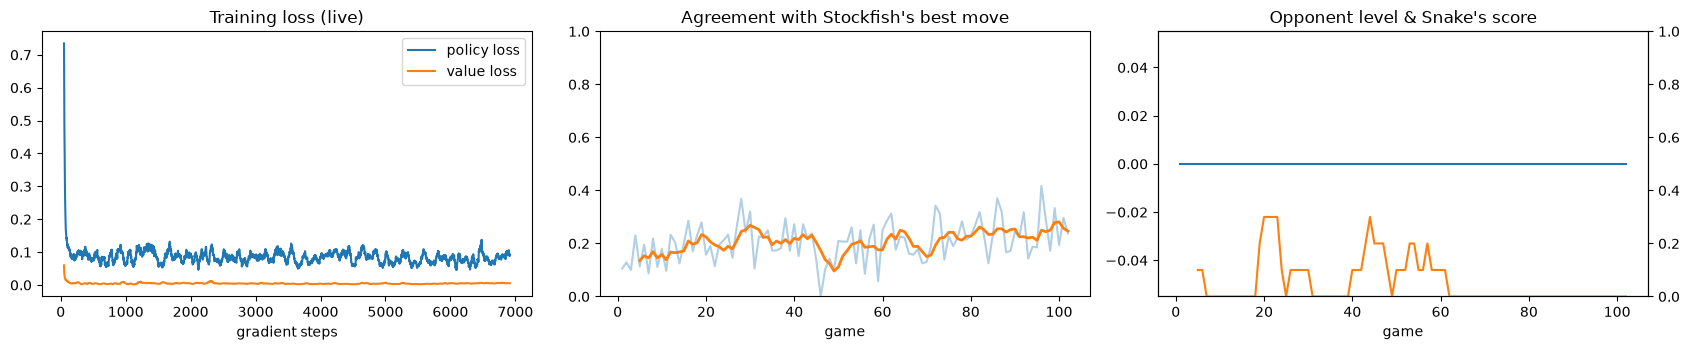

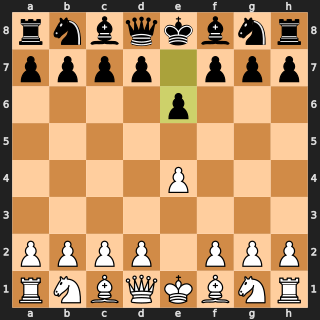

status=running | games=102 | opponent level=0 | positions in DB=3713 | steps=6916 | recent agreement=24.5%
last game: {'game': 102, 'score': 0.0, 'level': 0, 'agree': 0.23809523809523808, 'result': '1-0', 'snake': 'black', 'opening': 'Unknown / out of book'}


In [8]:
monitor(session, seconds=900, every=4)     # live board + loss curves; re-run any time

In [9]:
# Look inside the database any time
print("positions:", db.count(), "| games:", db.count("games"))
for row in db.query("SELECT id, snake_color, sf_level, result, termination, opening, n_plies FROM games ORDER BY id DESC LIMIT 8"):
    print(row)
print()
print("Agreement with Stockfish by game phase:")
for row in db.query("SELECT phase, COUNT(*), ROUND(AVG(agreed),3) FROM positions GROUP BY phase"):
    print(row)

positions: 3713 | games: 103
(103, 'white', 0, None, None, None, None)
(102, 'black', 0, '1-0', 'CHECKMATE', 'Unknown / out of book', 43)
(101, 'white', 0, '0-1', 'CHECKMATE', 'French Defence', 54)
(100, 'black', 0, '1-0', 'CHECKMATE', 'Reti Opening', 73)
(99, 'white', 0, '0-1', 'CHECKMATE', 'French Defence', 24)
(98, 'black', 0, '1-0', 'CHECKMATE', 'Reti Opening', 59)
(97, 'white', 0, '0-1', 'CHECKMATE', 'Ruy Lopez', 76)
(96, 'black', 0, '1-0', 'CHECKMATE', 'Reti Opening', 25)

Agreement with Stockfish by game phase:
('endgame', 675, 0.243)
('middlegame', 2060, 0.154)
('opening', 978, 0.272)


In [10]:
# session.stop()     # <- uncomment to stop & save (also saves automatically every few games)

### Optional: benchmark (no learning, no teacher forcing)
Plays Snake (with lookahead) against Stockfish at a fixed Skill Level and reports its score. Run it after a decent amount of training.

In [11]:
def arena(agent, level=0, games=4, movetime=0.05, lookahead=True, max_plies=200, show_last=True):
    eng = chess.engine.SimpleEngine.popen_uci(SF_PATH)
    eng.configure({"Skill Level": level, "Threads": 1})
    pts, last = 0.0, None
    try:
        for g in range(games):
            snake_white = g % 2 == 0
            b = chess.Board()
            while not b.is_game_over(claim_draw=True) and b.ply() < max_plies:
                if (b.turn == chess.WHITE) == snake_white:
                    b.push(agent.select_move(b, lookahead=lookahead))
                else:
                    b.push(eng.play(b, chess.engine.Limit(time=movetime)).move)
            r = b.result(claim_draw=True) if b.is_game_over(claim_draw=True) else "1/2-1/2"
            pts += {"1-0": 1.0, "0-1": 0.0}.get(r, .5) if snake_white else {"1-0": 0.0, "0-1": 1.0}.get(r, .5)
            last = b
    finally:
        eng.quit()
    print(f"Snake vs Stockfish level {level}: {pts}/{games}")
    if show_last and last: display(SVG(chess.svg.board(last, size=300)))
    return pts / games

# arena(agent, level=0, games=4)

## Part 6 — Website on `localhost`

This writes `snake_web.py` (Flask app + a single-page chess UI) and serves it from inside the notebook, using the **same live `agent`** that is training. Open <http://127.0.0.1:5000> in your browser.

* Click a piece → legal target squares are highlighted (the server re-validates every move with the **legal-move identifier**).
* The page also shows the detected **opening**, game **phase** and how the game ended (**game identifier**).
* *Smart mode* = mate-in-1 detection + 1-ply value-head lookahead on top of the raw policy.

In [12]:
%%writefile snake_web.py
"""snake_web.py - Flask website + JSON API for Snake (used locally AND when deployed)."""
import chess
from flask import Flask, jsonify, request, Response
from snake_core import identify_game

INDEX_HTML = r"""<!doctype html>
<html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Snake - AI Chess Bot</title>
<style>
  :root{--light:#f0d9b5;--dark:#b58863;--bg:#1e1e24;--card:#2a2a33;--text:#ececf1;--accent:#6ee7a8}
  *{box-sizing:border-box} body{margin:0;background:var(--bg);color:var(--text);font-family:system-ui,Segoe UI,Roboto,sans-serif;
  display:flex;flex-direction:column;align-items:center;padding:16px}
  h1{margin:8px 0 2px;font-size:1.6rem} h1 span{color:var(--accent)} .sub{opacity:.7;margin-bottom:14px;font-size:.9rem}
  #wrap{display:flex;flex-wrap:wrap;gap:20px;justify-content:center;width:100%;max-width:900px}
  #board{display:grid;grid-template-columns:repeat(8,1fr);width:min(92vw,520px);aspect-ratio:1;border:4px solid #444;border-radius:6px;overflow:hidden}
  .sq{display:flex;align-items:center;justify-content:center;position:relative;cursor:pointer;user-select:none;
      font-size:min(9vw,52px);line-height:1}
  .sq.l{background:var(--light)} .sq.d{background:var(--dark)}
  .sq.sel{outline:4px solid #4da3ff;outline-offset:-4px} .sq.last{box-shadow:inset 0 0 0 100px rgba(255,235,59,.38)}
  .sq.chk{box-shadow:inset 0 0 0 100px rgba(255,60,60,.5)}
  .sq.tgt::after{content:"";width:28%;height:28%;border-radius:50%;background:rgba(0,0,0,.28);position:absolute}
  .sq.tgt.cap::after{width:88%;height:88%;background:none;border:5px solid rgba(0,0,0,.3)}
  .w{color:#fff;text-shadow:0 0 2px #000,0 0 2px #000,0 0 3px #000} .b{color:#111;text-shadow:0 0 1px #fff}
  .coord{position:absolute;font-size:10px;opacity:.65;color:#000} .coord.r{top:2px;left:3px} .coord.f{bottom:1px;right:3px}
  #panel{background:var(--card);border-radius:10px;padding:16px;width:min(92vw,300px);display:flex;flex-direction:column;gap:10px}
  #status{font-weight:600;min-height:2.6em} .row{display:flex;gap:8px;flex-wrap:wrap}
  button{background:var(--accent);color:#102;border:0;border-radius:8px;padding:9px 12px;font-weight:700;cursor:pointer}
  button.alt{background:#44445a;color:var(--text)} button:disabled{opacity:.5;cursor:wait}
  #moves{font-family:ui-monospace,Menlo,monospace;font-size:.85rem;max-height:170px;overflow:auto;background:#222229;border-radius:6px;padding:8px;min-height:44px}
  .tag{font-size:.8rem;opacity:.8} label{font-size:.85rem;display:flex;gap:6px;align-items:center}
</style></head><body>
<h1>&#128013; <span>Snake</span> - AI Chess Bot</h1>
<div class="sub">A neural network trained live against Stockfish</div>
<div id="wrap">
  <div id="board"></div>
  <div id="panel">
    <div id="status">Loading...</div>
    <div class="tag" id="info"></div>
    <div class="row">
      <button onclick="newGame('white')">Play White</button>
      <button onclick="newGame('black')" class="alt">Play Black</button>
    </div>
    <label><input type="checkbox" id="look" checked> Smart mode (1-ply lookahead)</label>
    <div id="moves"></div>
    <div class="tag" id="stats"></div>
  </div>
</div>
<script>
const GLYPH={k:"\u265A\uFE0E",q:"\u265B\uFE0E",r:"\u265C\uFE0E",b:"\u265D\uFE0E",n:"\u265E\uFE0E",p:"\u265F\uFE0E"};
let moves=[], st=null, me="white", sel=null, busy=false;

async function api(path, body){
  const r=await fetch(path,{method:body?"POST":"GET",headers:{"Content-Type":"application/json"},body:body?JSON.stringify(body):undefined});
  const j=await r.json(); if(!r.ok) throw new Error(j.error||"error"); return j;
}
function parseFen(fen){
  const rows=fen.split(" ")[0].split("/"), g={};
  rows.forEach((row,i)=>{let f=0;for(const ch of row){if(/\d/.test(ch)){f+=+ch}else{g["abcdefgh"[f]+(8-i)]=ch;f++}}});
  return g;
}
function render(){
  const g=parseFen(st.fen), last=moves.length?moves[moves.length-1]:null, el=document.getElementById("board");
  el.innerHTML="";
  const files=me==="white"?"abcdefgh":"hgfedcba", ranks=me==="white"?[8,7,6,5,4,3,2,1]:[1,2,3,4,5,6,7,8];
  const targets=sel&&st.legal[sel]?st.legal[sel]:[];
  ranks.forEach((r,ri)=>files.split("").forEach((f,fi)=>{
    const s=f+r, d=document.createElement("div"), light=("abcdefgh".indexOf(f)+r)%2===1;
    d.className="sq "+(light?"l":"d");
    if(s===sel)d.classList.add("sel");
    if(last&&(s===last.slice(0,2)||s===last.slice(2,4)))d.classList.add("last");
    if(targets.includes(s)){d.classList.add("tgt");if(g[s])d.classList.add("cap")}
    const p=g[s];
    if(p){ if(p.toLowerCase()==="k"&&st.in_check&&((p===p.toUpperCase())===(st.turn==="white")))d.classList.add("chk");
      d.innerHTML=`<span class="${p===p.toUpperCase()?"w":"b"}">${GLYPH[p.toLowerCase()]}</span>`;}
    if(fi===0){const c=document.createElement("span");c.className="coord r";c.textContent=r;d.appendChild(c)}
    if(ri===7){const c=document.createElement("span");c.className="coord f";c.textContent=f;d.appendChild(c)}
    d.onclick=()=>clickSq(s);
    el.appendChild(d);
  }));
  let txt;
  if(st.over){txt=st.result==="1/2-1/2"?`Draw (${st.termination.toLowerCase().replace(/_/g," ")})`:
      `${st.winner==="white"?"White":"Black"} wins by ${st.termination.toLowerCase().replace(/_/g," ")}`+((st.winner===me)?" - you win!":" - Snake wins")}
  else txt=st.turn===me?"Your move"+(st.in_check?" (you are in check!)":""):"Snake is thinking...";
  document.getElementById("status").textContent=txt;
  document.getElementById("info").textContent=`Opening: ${st.info.opening} | Phase: ${st.info.phase} | Move ${Math.floor(st.info.ply/2)+1}`;
  const san=st.san||[]; let h="";
  for(let i=0;i<san.length;i+=2)h+=`${i/2+1}. ${san[i]} ${san[i+1]||""}<br>`;
  const mv=document.getElementById("moves"); mv.innerHTML=h||"<i>No moves yet</i>"; mv.scrollTop=mv.scrollHeight;
}
async function clickSq(s){
  if(busy||st.over||st.turn!==me)return;
  const g=parseFen(st.fen);
  if(sel&&st.legal[sel]&&st.legal[sel].includes(s)){
    const uci=sel+s; sel=null; busy=true;
    try{ st=await api("/api/move",{moves,move:uci,lookahead:document.getElementById("look").checked}); moves=st.moves; }
    catch(e){alert(e.message)} busy=false; render(); return;
  }
  sel=(g[s]&&st.legal[s])?s:null; render();
}
async function newGame(color){
  me=color; sel=null; moves=[]; busy=true;
  st=await api("/api/state",{moves:[]}); render();
  if(me==="black"){ st=await api("/api/snake",{moves,lookahead:document.getElementById("look").checked}); moves=st.moves; }
  busy=false; render();
}
async function loadStats(){
  try{const s=await api("/api/stats"); document.getElementById("stats").textContent=
    `Snake has trained for ${s.train_steps} steps over ${s.games} games (Stockfish level ${s.sf_level}).`}catch(e){}
}
newGame("white"); loadStats();
</script></body></html>"""


def _build_board(moves):
    board = chess.Board()
    for u in moves:
        board.push_uci(u)          # raises ValueError if illegal -> handled by caller
    return board


def _state(board):
    legal = {}
    for m in board.legal_moves:
        legal.setdefault(chess.square_name(m.from_square), []).append(chess.square_name(m.to_square))
    replay, san = chess.Board(), []
    for m in board.move_stack:
        san.append(replay.san(m)); replay.push(m)
    info = identify_game(board)
    return {"fen": board.fen(), "moves": [m.uci() for m in board.move_stack], "san": san,
            "turn": "white" if board.turn else "black", "legal": legal, "in_check": board.is_check(),
            "over": info["over"], "result": info["result"], "termination": info["termination"],
            "winner": info["winner"], "info": info}


def create_app(agent, stats_fn=None):
    app = Flask(__name__)

    def bad(msg, code=400):
        return jsonify({"error": msg}), code

    def read_board():
        data = request.get_json(force=True, silent=True) or {}
        try:
            return _build_board(data.get("moves", [])), data
        except (ValueError, TypeError):
            return None, data

    @app.get("/")
    def index():
        return Response(INDEX_HTML, mimetype="text/html")

    @app.get("/health")
    def health():
        return jsonify(ok=True)

    @app.get("/api/stats")
    def stats():
        s = stats_fn() if stats_fn else dict(agent.meta)
        return jsonify({"train_steps": s.get("train_steps", agent.meta.get("train_steps", 0)),
                        "games": s.get("games", agent.meta.get("games", 0)),
                        "sf_level": s.get("sf_level", agent.meta.get("sf_level", 0))})

    @app.post("/api/state")
    def state():
        board, _ = read_board()
        return bad("invalid move list") if board is None else jsonify(_state(board))

    @app.post("/api/move")
    def move():
        board, data = read_board()
        if board is None:
            return bad("invalid move list")
        if board.is_game_over(claim_draw=True):
            return bad("game is over")
        uci = str(data.get("move", ""))
        try:
            m = chess.Move.from_uci(uci)
        except ValueError:
            return bad("malformed move")
        piece = board.piece_at(m.from_square)            # auto-queen
        if piece and piece.piece_type == chess.PAWN and chess.square_rank(m.to_square) in (0, 7) and not m.promotion:
            m.promotion = chess.QUEEN
        if m not in board.legal_moves:                   # LEGAL MOVE IDENTIFIER on the server side
            return bad(f"illegal move: {uci}")
        board.push(m)
        if not board.is_game_over(claim_draw=True):
            board.push(agent.select_move(board, lookahead=bool(data.get("lookahead", True))))
        return jsonify(_state(board))

    @app.post("/api/snake")
    def snake():
        board, data = read_board()
        if board is None:
            return bad("invalid move list")
        if board.is_game_over(claim_draw=True):
            return bad("game is over")
        board.push(agent.select_move(board, lookahead=bool(data.get("lookahead", True))))
        return jsonify(_state(board))

    return app

Writing snake_web.py


In [13]:
import importlib, snake_web; importlib.reload(snake_web)
from snake_web import create_app
from werkzeug.serving import make_server

class ServerThread(threading.Thread):
    def __init__(self, app, host="127.0.0.1", port=5000):
        super().__init__(daemon=True)
        self.server = make_server(host, port, app, threaded=True)
    def run(self): self.server.serve_forever()
    def shutdown(self): self.server.shutdown()

def live_stats():
    return {"train_steps": agent.meta["train_steps"], "games": agent.meta.get("games", 0),
            "sf_level": session.level}

app = create_app(agent, stats_fn=live_stats)
try:
    server.shutdown()          # restart if re-running this cell
except NameError:
    pass
server = ServerThread(app, port=5000)
server.start()
print("Snake is live at  http://127.0.0.1:5000   (stop with server.shutdown())")

Snake is live at  http://127.0.0.1:5000   (stop with server.shutdown())


## Part 7 — Put it on a real website

A public site only needs **Snake's weights + the Flask app** (no Stockfish, no database). This cell builds a `deploy/` folder with everything:

```
deploy/
  app.py  snake_core.py  snake_web.py  snake_model.pt
  requirements.txt  Dockerfile  README.md
```

**Option A — Hugging Face Spaces (free, easiest for ML bots)**
1. Create an account → *New Space* → SDK: **Docker** → blank.
2. Upload everything inside `deploy/` (drag-and-drop in the web UI, or `git push`). The included `README.md` already has the Space header (`sdk: docker`, `app_port: 7860`).
3. The Space builds and gives you a public URL like `https://<you>-snake.hf.space`.

**Option B — Render / Railway / Fly.io:** push `deploy/` to a GitHub repo → create a *Web Service* from the repo → it detects the `Dockerfile` and serves on `$PORT` automatically.

**Option C — your own VPS:** `docker build -t snake . && docker run -p 80:7860 snake`

> Free-tier limits (RAM, sleeping apps) change over time, so check the provider's current docs. The model is ~35 MB and runs on CPU, so the smallest tier is enough for light use.
>
> Re-run this cell after more training to refresh `deploy/snake_model.pt`, then re-upload that one file.

In [14]:
import shutil
from pathlib import Path

agent.save(cfg.model_path)                         # make sure the latest weights are on disk
d = Path("deploy"); d.mkdir(exist_ok=True)
for f in ["snake_core.py", "snake_web.py"]:
    shutil.copy(f, d / f)
shutil.copy(cfg.model_path, d / "snake_model.pt")

(d / "app.py").write_text("""import os
from snake_core import SnakeAgent
from snake_web import create_app

agent = SnakeAgent.load(os.environ.get("SNAKE_MODEL", "snake_model.pt"), device="cpu")
app = create_app(agent)

if __name__ == "__main__":
    app.run(host="0.0.0.0", port=int(os.environ.get("PORT", 7860)))
""")
(d / "requirements.txt").write_text("flask\ngunicorn\npython-chess\nnumpy\n")
(d / "Dockerfile").write_text("""FROM python:3.11-slim
WORKDIR /app
RUN pip install --no-cache-dir torch --index-url https://download.pytorch.org/whl/cpu
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY . .
ENV PORT=7860
EXPOSE 7860
CMD gunicorn -b 0.0.0.0:${PORT} -w 1 --threads 4 --timeout 120 app:app
""")
(d / "README.md").write_text("""---
title: Snake Chess Bot
emoji: 🐍
colorFrom: green
colorTo: gray
sdk: docker
app_port: 7860
---

# Snake - AI chess bot
Neural-network chess bot trained live against Stockfish (GPLv3, used as an external UCI engine).
This project uses python-chess (GPL-3.0+); distribute it under GPLv3-compatible terms and provide the source.
""")
print("Deploy bundle ready:", sorted(p.name for p in d.iterdir()))
print("Model size: %.1f MB" % (os.path.getsize(d / "snake_model.pt") / 1e6))

Deploy bundle ready: ['Dockerfile', 'README.md', 'app.py', 'requirements.txt', 'snake_core.py', 'snake_model.pt', 'snake_web.py']
Model size: 35.0 MB


### Test the deploy bundle locally (optional)
```bash
cd deploy
pip install -r requirements.txt   # + torch
python app.py                     # then open http://127.0.0.1:7860
```

## Where to go next
* **Make Snake stronger:** more games / GPU; bigger net (`SnakeAgent(channels=128, blocks=8)`); `teacher_time=0.2`; add multi-PV soft targets; add a real tree search (MCTS) driven by the value head.
* **Learn from website visitors:** log human-vs-Snake positions into `positions`, label them with Stockfish offline, and fine-tune.
* **Self-play phase:** once Snake beats Stockfish level ~5, add Snake-vs-Snake games labelled by the value head + game result (AlphaZero-style).